# Streaming ideas, made visible

Optional, self-paced: goes deeper than Session 4.3.

**No exercises:** run every cell and look at the courier events. You practise in **Lab 4.3**.

Kafka and Flink are big systems, but the ideas underneath are small enough to print. Here we look at them on a
handful of real Qafila courier events:

1. A topic is a set of partitioned, append-only logs
2. Offsets and consumer groups: reading doesn't delete
3. Commit before or after processing? Lost vs. duplicated
4. Two clocks: event time vs. processing time
5. Windows: tumbling, hopping, session
6. Watermarks: when is a window finished?
7. The same ideas in a real engine

🤔 asks you to predict **before** you run the cell.

In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/SDAIAAcademy/data-engineering.git"
    if not Path("/content/data-engineering").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/data-engineering"], check=True)
    os.chdir("/content/data-engineering/labs")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
else:
    while not Path("de_utils.py").exists() and Path.cwd() != Path.cwd().parent:
        os.chdir("..")  # demos/ notebooks run from labs/
sys.path.insert(0, os.getcwd())

import de_utils as U
U.ensure_data()
print("data:", U.RAW, "| quick mode:", U.QUICK)

data: /content/data-engineering/labs\data\raw | quick mode: False


In [2]:
import json
import zlib
from datetime import timedelta

import pandas as pd

pd.set_option("display.width", 200)
events = [json.loads(line) for line in open(U.RAW / "events" / "delivery_events.jsonl", encoding="utf-8")]
print(f"{len(events):,} courier events, in the order the platform received them")
pd.DataFrame(events[:6])[["event_id", "order_id", "city", "courier_id", "event_type", "event_time", "ingest_time"]]

22,518 courier events, in the order the platform received them


,event_id,order_id,city,courier_id,event_type,event_time,ingest_time
0,ev-0001457,5040442,Jeddah,CR-JED-031,assigned,2026-09-24T05:14:52.016+03:00,2026-09-24T02:14:57.317Z
1,ev-0001458,5040442,Jeddah,CR-JED-031,picked_up,2026-09-24T05:24:21.703+03:00,2026-09-24T02:24:26.653Z
2,ev-0001459,5040442,Jeddah,CR-JED-031,out_for_delivery,2026-09-24T05:25:21.467+03:00,2026-09-24T02:25:25.410Z
3,ev-0001460,5040442,Jeddah,CR-JED-031,delivered,2026-09-24T05:41:57.809+03:00,2026-09-24T02:42:04.535Z
4,ev-0000727,5040253,Jeddah,CR-JED-055,assigned,2026-09-24T03:18:54.099Z,2026-09-24T03:19:01.801Z
5,ev-0000728,5040253,Jeddah,CR-JED-055,picked_up,2026-09-24T03:26:37.789Z,2026-09-24T03:26:41.352Z


## 1 · A topic is a set of partitioned, append-only logs

A **partition** is a list you only append to; a record's position is its **offset**. The producer picks the
partition by hashing the record's **key**. That's all a Kafka topic is, minus replication and disks:

In [3]:
class Log:
    """A tiny Kafka topic: N partitions, each an append-only list; a record's offset is its index."""

    def __init__(self, partitions: int):
        self.parts = [[] for _ in range(partitions)]

    def produce(self, key, value) -> tuple[int, int]:
        p = zlib.crc32(str(key).encode()) % len(self.parts)
        self.parts[p].append(value)
        return p, len(self.parts[p]) - 1          # (partition, offset)

🤔 We produce the first 18 events, keyed by `order_id`, into 3 partitions. Will one order's events stay together? In
order?

In [4]:
topic = Log(3)
for e in events[:18]:
    topic.produce(e["order_id"], e)

def show(log):
    cols = {f"P{p}": [f"…{e['order_id'] % 1000:03d} {e['event_type']}" for e in part] for p, part in enumerate(log.parts)}
    return pd.DataFrame({k: pd.Series(v) for k, v in cols.items()}).fillna("").rename_axis("offset")

show(topic)

,P0,P1,P2
offset,,,
0,…253 assigned,…442 assigned,…479 assigned
1,…253 picked_up,…442 picked_up,…479 picked_up
2,…253 out_for_delivery,…442 out_for_delivery,…479 out_for_delivery
3,…253 delivered,…442 delivered,…479 out_for_delivery
4,,…483 assigned,…479 delivered
5,,…483 picked_up,…832 assigned
6,,…483 out_for_delivery,…832 picked_up


Every order lives in exactly one partition, and its `assigned → picked_up → out_for_delivery → delivered` stays in
order there. Across partitions there's **no** order: P0's offset 3 and P1's offset 3 have nothing to do with each
other. Choose the key for the ordering you need. Partitions are also the unit of **parallelism**: 3 partitions, at
most 3 consumers in one group.

## 2 · Offsets and consumer groups: reading doesn't delete

Two teams read the same topic. Each **consumer group** keeps its own committed offset per partition.

In [5]:
committed = {"sla-dashboard": [0, 0, 0], "fraud": [0, 0, 0]}

def consume(group, max_per_partition):
    for p, part in enumerate(topic.parts):
        start = committed[group][p]
        got = part[start:start + max_per_partition]
        committed[group][p] = start + len(got)       # commit after reading

consume("sla-dashboard", 2)
consume("fraud", 10)
print("records in each partition:", [len(p) for p in topic.parts])
pd.DataFrame(committed, index=["P0", "P1", "P2"]).T.rename_axis("group: next offset to read")

records in each partition: [4, 7, 7]


,P0,P1,P2
group: next offset to read,,,
sla-dashboard,2,2,2
fraud,4,7,7


The groups are independent, and the log is untouched: Kafka **retains** records for days (or forever with tiered
storage). A new group can start at offset 0 and **replay** history: that's how you fix a bug in a stream job or
backfill a new metric.

## 3 · Commit before or after processing? Lost vs. duplicated

The job counts **delivered** events. It reads batches of 100 events and crashes once, halfway through batch 5.

🤔 One consumer commits its offset **before** processing each batch, the other **after**. Which one loses data,
and which one double-counts?

In [6]:
def run(commit_first: bool, crash_in_batch=5, size=100):
    committed, position, counted, n = 0, 0, 0, 0
    while position < len(events):
        batch = events[position:position + size]
        position += len(batch)
        n += 1
        if commit_first:
            committed = position
        crashed = n == crash_in_batch
        for e in batch[:size // 2] if crashed else batch:   # 💥 the crash stops processing halfway
            counted += e["event_type"] == "delivered"
        if crashed:
            position = committed                            # restart from the last committed offset
            continue
        if not commit_first:
            committed = position
    return counted

raw_truth = sum(e["event_type"] == "delivered" for e in events)
pd.DataFrame({"delivered events counted": [raw_truth, run(commit_first=True), run(commit_first=False)]},
             index=["no crash", "commit → process (at-most-once)", "process → commit (at-least-once)"]).assign(
    difference=lambda d: d.iloc[:, 0] - raw_truth)

,delivered events counted,difference
no crash,5327,0
commit → process (at-most-once),5315,-12
process → commit (at-least-once),5340,13


- **Commit first**: after the restart, the consumer resumes after the batch it never finished. Those events are **lost**.
- **Commit after**: it re-reads the batch and counts the first half **again**.

Neither is "exactly-once". The production answer is at-least-once **plus** an idempotent or transactional sink, so a
replay changes nothing. And there's a second source of duplicates the consumer can't prevent: the phones themselves.

In [7]:
dupes = len(events) - len({e["event_id"] for e in events})
print(f"{dupes} events arrived twice from the producer side (phones retrying), before any crash")

312 events arrived twice from the producer side (phones retrying), before any crash


Lab 4.3 makes the consumer idempotent and gets the exact counts despite both problems.

## 4 · Two clocks: event time vs. processing time

Every event carries `event_time` (on the courier's phone, when it happened) and `ingest_time` (when the platform got
it). And two app versions write `event_time` in **three** formats:

In [8]:
fmt = lambda s: "epoch millis" if s.isdigit() else "+03:00 offset" if "+" in s else "Z (UTC)"
pd.DataFrame(events).assign(format=lambda d: d.event_time.map(fmt)).groupby("format").agg(
    events=("event_id", "size"), example=("event_time", "first"))

,events,example
format,,
+03:00 offset,18031,2026-09-24T05:14:52.016+03:00
Z (UTC),3372,2026-09-24T03:18:54.099Z
epoch millis,1115,1790220454190


DuckDB reads the JSON lines and parses both clocks into one type, so we can ask how late events arrive.

🤔 Most events arrive within seconds. How late is the **latest** one?

In [9]:
import duckdb

df = duckdb.sql(f"""
    SELECT event_id, order_id, city, courier_id, event_type,
           CASE WHEN regexp_full_match(event_time, '[0-9]+') THEN make_timestamptz(event_time::BIGINT * 1000)
                ELSE event_time::TIMESTAMPTZ END AS ts,
           ingest_time::TIMESTAMPTZ AS arrived
    FROM read_json('{(U.RAW / "events" / "delivery_events.jsonl").as_posix()}', columns = {{
        event_id: 'VARCHAR', order_id: 'BIGINT', city: 'VARCHAR', courier_id: 'VARCHAR',
        event_type: 'VARCHAR', event_time: 'VARCHAR', ingest_time: 'VARCHAR'}})
""").df()
df["ts"], df["arrived"] = df.ts.dt.tz_convert("Asia/Riyadh"), df.arrived.dt.tz_convert("Asia/Riyadh")   # Riyadh time
df["late_s"] = (df.arrived - df.ts).dt.total_seconds()
df.late_s.describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_frame("seconds late")

,seconds late
count,22518.0
mean,28.3
std,215.9
min,0.3
50%,4.2
90%,7.4
99%,1065.6
max,2991.3


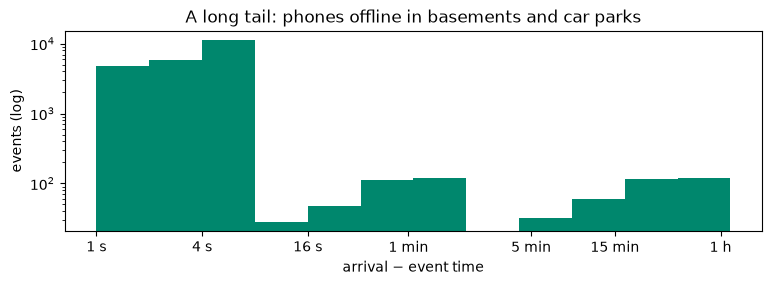

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 2.6))
ax.hist(df.late_s.clip(lower=1), bins=[2 ** i for i in range(0, 13)], color="#00876d")
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks([1, 4, 16, 60, 300, 900, 3600], ["1 s", "4 s", "16 s", "1 min", "5 min", "15 min", "1 h"])
ax.set_xlabel("arrival − event time")
ax.set_ylabel("events (log)")
ax.set_title("A long tail: phones offline in basements and car parks")
plt.show()

"Deliveries between 21:00 and 21:15" means **event time**. But a delivery at 21:12 may only arrive at 21:55. So every
windowed metric has to decide how long to wait.

## 5 · Windows: tumbling, hopping, session

Take one delivered event and see which windows it belongs to.

In [11]:
e = df[df.event_type == "delivered"].iloc[100]
ts = e.ts
tumbling = ts.floor("15min")
hopping = [ts.floor("5min") - timedelta(minutes=m) for m in (10, 5, 0)]
print(f"event at {ts:%H:%M:%S}")
print(f"tumbling 15 min           → [{tumbling:%H:%M}, {tumbling + timedelta(minutes=15):%H:%M})   exactly one window")
print("hopping 15 min, every 5   →", ", ".join(f"[{h:%H:%M}, {h + timedelta(minutes=15):%H:%M})" for h in hopping),
      f"  {len(hopping)} windows")

event at 10:22:14
tumbling 15 min           → [10:15, 10:30)   exactly one window
hopping 15 min, every 5   → [10:10, 10:25), [10:15, 10:30), [10:20, 10:35)   3 windows


**Session** windows have no fixed size: they close after a gap of inactivity. One courier's day, split wherever
they had no event for 30 minutes:

In [12]:
courier = df[df.courier_id == e.courier_id].sort_values("ts")
day = courier[courier.ts.dt.date == ts.date()]
session = (day.ts.diff() > timedelta(minutes=30)).cumsum()
day.groupby(session).agg(start=("ts", "min"), end=("ts", "max"), events=("event_id", "size"),
                         orders=("order_id", "nunique")).assign(
    start=lambda d: d.start.dt.strftime("%H:%M"), end=lambda d: d.end.dt.strftime("%H:%M")).rename_axis(f"{e.courier_id} session")

,start,end,events,orders
CR-DAM-013 session,,,,
0,09:47,10:22,4,1
1,19:07,19:33,4,1
2,21:14,21:35,4,1


## 6 · Watermarks: when is a window finished?

A stream engine can't wait forever. It tracks a **watermark**: W = (max event time seen so far) − (allowed lateness).
"I believe I've seen everything before W." When W passes a window's end, the window is emitted and its state dropped.
An event for an already-closed window is **late** and gets dropped.

Here's the rule on a few Riyadh deliveries, in arrival order, with **5 minutes** of allowed lateness.

🤔 Which of these events will be dropped?

In [13]:
riyadh = df[(df.city == "Riyadh") & (df.event_type == "delivered")].reset_index(drop=True)
late_i = riyadh.index[riyadh.late_s.between(22 * 60, 40 * 60)][3]       # a delivery that arrived 22-40 min late
trace = riyadh.iloc[late_i - 5: late_i + 3].copy()

allowed = timedelta(minutes=5)
trace["window"] = trace.ts.dt.floor("15min")
trace["max_event_time_seen"] = riyadh.ts.cummax().iloc[late_i - 5: late_i + 3]
trace["watermark"] = trace.max_event_time_seen - allowed
trace["verdict"] = ["LATE → dropped" if w + timedelta(minutes=15) <= wm else "on time"
                    for w, wm in zip(trace.window, trace.watermark)]
fmt_t = lambda s: s.dt.strftime("%H:%M:%S")
trace.assign(**{c: fmt_t(trace[c]) for c in ["arrived", "ts", "max_event_time_seen", "watermark"]},
             window=fmt_t(trace.window).str[:5])[
    ["order_id", "arrived", "ts", "window", "max_event_time_seen", "watermark", "verdict"]]

,order_id,arrived,ts,window,max_event_time_seen,watermark,verdict
384,5040664,22:33:31,22:33:25,22:30,22:33:25,22:28:25,on time
385,5040264,22:34:48,22:34:42,22:30,22:34:42,22:29:42,on time
386,5040528,22:35:31,22:35:26,22:30,22:35:26,22:30:26,on time
387,5040591,22:40:10,22:40:08,22:30,22:40:08,22:35:08,on time
388,5040087,22:40:12,22:40:08,22:30,22:40:08,22:35:08,on time
389,5040491,22:40:55,22:04:29,22:00,22:40:08,22:35:08,LATE → dropped
390,5040550,22:41:32,22:41:24,22:30,22:41:24,22:36:24,on time
391,5040137,22:43:42,22:43:34,22:30,22:43:34,22:38:34,on time


The late event's 15-minute window had already closed: the watermark (driven by **other** couriers' fresh events)
passed its end. With more allowed lateness it would have been counted, but every window would also be emitted later.

The same rule over a busy hour, drawn. Each dot is a delivery: x = when it arrived, y = when it happened. The step line
is the watermark; red ✕ are dropped. Left: 2 minutes of patience. Right: 30 minutes.

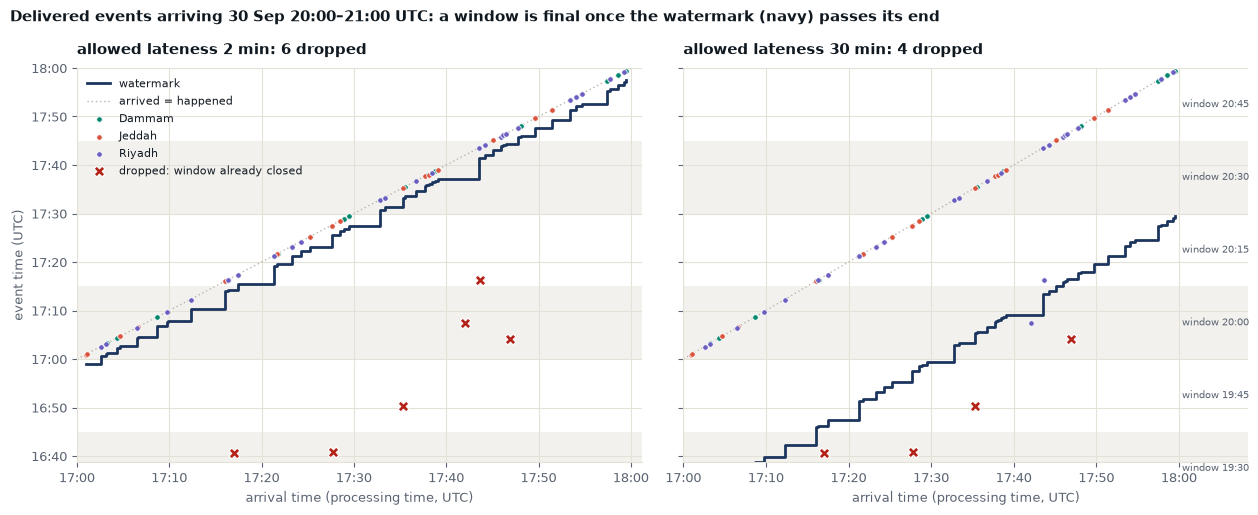

In [14]:
import de_viz as V

stream = [{"ts": r.ts.to_pydatetime(), "arrived": r.arrived.to_pydatetime(), "event_type": r.event_type, "city": r.city}
          for r in df.itertuples()]
V.watermark(stream, [timedelta(minutes=2), timedelta(minutes=30)])

**Latency vs. completeness** is a business decision, not a technical one. Ops wants the SLA board within 2 minutes and
can live with a slightly low number; finance wants exact totals and can wait (or recompute in batch tonight).

## 7 · The same ideas in a real engine

Everything above has a name in Spark Structured Streaming (and in Flink SQL, Kafka Streams, RisingWave...). Shown for
reading, not run here:

```python
(spark.readStream.format("kafka")                                    # the log
      .option("subscribe", "delivery-events")                        # a topic
      .option("startingOffsets", "earliest").load()                  # offsets: replay from 0
      .select(F.from_json("value", schema).alias("e")).select("e.*")
      .withWatermark("event_ts", "10 minutes")                       # allowed lateness
      .dropDuplicatesWithinWatermark(["event_id"])                   # producer duplicates
      .filter("event_type = 'delivered'")
      .groupBy(F.window("event_ts", "15 minutes"), "city").count()   # tumbling window, by event time
      .writeStream.option("checkpointLocation", "s3://…/chk")        # committed offsets + state
      .toTable("lake.silver.deliveries_15m"))
```

## Recap → Lab 4.3

| We saw | Because |
|---|---|
| one order stayed in one partition, in order | key → partition; order is per partition only |
| two groups at different offsets, log unchanged | consumers track offsets; reading doesn't delete |
| commit-first lost events, commit-after double-counted | the crash falls between processing and committing |
| some events arrive ~50 min late | event time ≠ processing time |
| the late delivery was dropped | the watermark had passed its window's end |

**Lab 4.3** builds the log and consumer on the full week, makes counting idempotent, and measures the watermark
trade-off.